# Customer Segmentation Analysis

**Oasis Infobyte Data Analytics Internship — Level 1, Task 2**

---

## 1. Business Problem

Understanding customer behaviour is critical for any e-commerce business. By segmenting customers into distinct groups based on their purchasing patterns, businesses can create targeted marketing strategies, improve customer retention, and optimize resource allocation.

## 2. Objective

Apply K-Means clustering to segment customers based on RFM (Recency, Frequency, Monetary) analysis, profile each segment, and provide actionable marketing recommendations.

## 3. Dataset Overview

We use the **UCI Online Retail Dataset**, which contains transactional data from a UK-based online retailer (2010–2011). This dataset includes invoice numbers, stock codes, descriptions, quantities, dates, prices, customer IDs, and countries.

**Source:** UCI Machine Learning Repository — Online Retail Dataset

## 4. Data Loading & Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import os
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

os.makedirs('outputs', exist_ok=True)

# Load the dataset
df = pd.read_excel('data/online_retail.xlsx')
print(f'Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns')
df.head()

Dataset loaded: 541,909 rows, 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Inspect structure
print('Dataset Info:')
print('='*50)
df.info()
print(f'\nShape: {df.shape}')
print(f'\nColumn names: {list(df.columns)}')

Dataset Info:


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Shape: (541909, 8)

Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [3]:
# Missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing': missing, '% Missing': missing_pct})
print('Missing Values:')
print(missing_df[missing_df['Missing'] > 0])
print(f'\nTotal rows with missing CustomerID: {df["CustomerID"].isnull().sum():,}')

Missing Values:
             Missing  % Missing
Description     1454       0.27
CustomerID    135080      24.93



Total rows with missing CustomerID: 135,080


**Observation:** The dataset has missing values in CustomerID and Description. Since we need CustomerID for RFM analysis, rows without a CustomerID must be removed.

## 5. Data Cleaning

In [4]:
print(f'Original shape: {df.shape}')

# Remove rows without CustomerID (can't do RFM without customer identification)
df = df.dropna(subset=['CustomerID'])
print(f'After removing null CustomerID: {df.shape}')

# Remove cancelled orders (InvoiceNo starting with 'C')
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
print(f'After removing cancelled orders: {df.shape}')

# Remove negative/zero quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print(f'After removing non-positive quantities/prices: {df.shape}')

# Remove duplicates
dupes = df.duplicated().sum()
df = df.drop_duplicates()
print(f'Duplicates removed: {dupes}')
print(f'Final clean shape: {df.shape}')

# Create TotalAmount column
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Ensure InvoiceDate is datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f'\nDate range: {df["InvoiceDate"].min()} to {df["InvoiceDate"].max()}')
print(f'Unique customers: {df["CustomerID"].nunique():,}')

Original shape: (541909, 8)


After removing null CustomerID: (406829, 8)


After removing cancelled orders: (397924, 8)
After removing non-positive quantities/prices: (397884, 8)


Duplicates removed: 5192
Final clean shape: (392692, 8)

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique customers: 4,338


## 6. Descriptive Statistics

In [5]:
# Transaction-level statistics
print('Transaction-Level Descriptive Statistics')
print('='*50)
print(df[['Quantity', 'UnitPrice', 'TotalAmount']].describe().round(2))

# Customer-level statistics
customer_stats = df.groupby('CustomerID').agg({
    'TotalAmount': ['sum', 'mean', 'count'],
    'InvoiceNo': 'nunique'
}).reset_index()
customer_stats.columns = ['CustomerID', 'TotalSpend', 'AvgPurchaseValue', 'TotalItems', 'PurchaseFrequency']

print(f'\nCustomer-Level Statistics')
print('='*50)
print(f'Average Purchase Value: {customer_stats["AvgPurchaseValue"].mean():.2f}')
print(f'Average Purchase Frequency: {customer_stats["PurchaseFrequency"].mean():.2f} orders')
print(f'Average Total Spend (Historical): {customer_stats["TotalSpend"].mean():.2f}')
print(f'Median Total Spend: {customer_stats["TotalSpend"].median():.2f}')

print(f'\nCustomer Lifetime Value Proxy (Historical Total Spend):')
print(customer_stats[['TotalSpend', 'AvgPurchaseValue', 'PurchaseFrequency']].describe().round(2))

Transaction-Level Descriptive Statistics
        Quantity  UnitPrice  TotalAmount
count  392692.00  392692.00    392692.00
mean       13.12       3.13        22.63
std       180.49      22.24       311.10
min         1.00       0.00         0.00
25%         2.00       1.25         4.95
50%         6.00       1.95        12.45
75%        12.00       3.75        19.80
max     80995.00    8142.75    168469.60



Customer-Level Statistics


Average Purchase Value: 68.38
Average Purchase Frequency: 4.27 orders
Average Total Spend (Historical): 2048.69
Median Total Spend: 668.57

Customer Lifetime Value Proxy (Historical Total Spend):
       TotalSpend  AvgPurchaseValue  PurchaseFrequency
count     4338.00           4338.00            4338.00
mean      2048.69             68.38               4.27
std       8985.23           1467.92               7.70
min          3.75              2.14               1.00
25%        306.48             12.39               1.00
50%        668.57             17.76               2.00
75%       1660.60             24.88               5.00
max     280206.02          77183.60             209.00


**Note on Customer Lifetime Value:** Since we only have a historical snapshot (not forward-looking data), the `TotalSpend` per customer serves as a proxy for CLV — it represents the total monetary value each customer has contributed during the observed period.

## 7. RFM Feature Engineering

**Why RFM?**

RFM analysis is a proven customer segmentation technique based on three behavioural dimensions:

- **Recency (R):** How recently a customer made a purchase. More recent = more engaged.
- **Frequency (F):** How often a customer purchases. Higher frequency = more loyal.
- **Monetary (M):** How much money a customer spends. Higher spending = more valuable.

These three features capture the most important aspects of customer purchasing behaviour and are widely used in marketing analytics.

In [6]:
# Set reference date as one day after the last transaction
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f'Reference date for Recency calculation: {reference_date}')

# Build RFM table
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,  # Recency
    'InvoiceNo': 'nunique',                                      # Frequency
    'TotalAmount': 'sum'                                         # Monetary
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print(f'\nRFM Table Shape: {rfm.shape}')
print(f'\nRFM Summary Statistics:')
print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))
rfm.head(10)

Reference date for Recency calculation: 2011-12-10 12:50:00



RFM Table Shape: (4338, 4)

RFM Summary Statistics:
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00    1660.60
max     374.00     209.00  280206.02


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


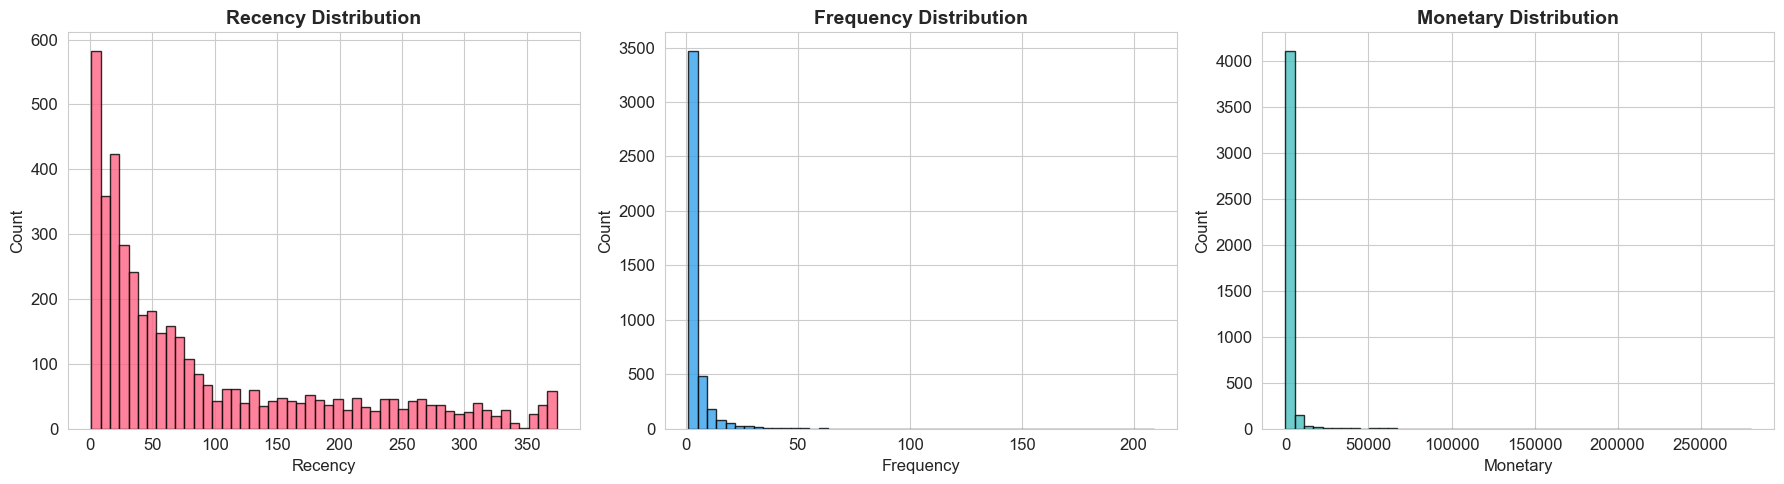

In [7]:
# Visualize RFM distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    axes[i].hist(rfm[col], bins=50, color=['#FF6384', '#36A2EB', '#4BC0C0'][i], edgecolor='black', alpha=0.8)
    axes[i].set_title(f'{col} Distribution', fontsize=14, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.savefig('outputs/rfm_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** The RFM distributions are typically right-skewed — most customers have low frequency and monetary values, with a few high-value outliers.

## 8. Data Normalization (StandardScaler)

In [8]:
# Apply log transformation to reduce skewness before scaling
rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].copy()
rfm_log['Frequency'] = np.log1p(rfm_log['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm_log['Monetary'])

# StandardScaler normalization
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])

print('Scaled RFM Statistics:')
print(rfm_scaled_df.describe().round(3))

Scaled RFM Statistics:
        Recency  Frequency  Monetary
count  4338.000   4338.000  4338.000
mean      0.000     -0.000    -0.000
std       1.000      1.000     1.000
min      -0.915     -0.955    -3.998
25%      -0.745     -0.955    -0.684
50%      -0.415     -0.362    -0.065
75%       0.495      0.653     0.657
max       2.815      5.859     4.732


## 9. K-Means Clustering — Elbow Method

K=2: Inertia=6874.93
K=3: Inertia=4299.07
K=4: Inertia=3243.03
K=5: Inertia=2760.79
K=6: Inertia=2396.85


K=7: Inertia=2166.96
K=8: Inertia=1961.09
K=9: Inertia=1819.16


K=10: Inertia=1687.78


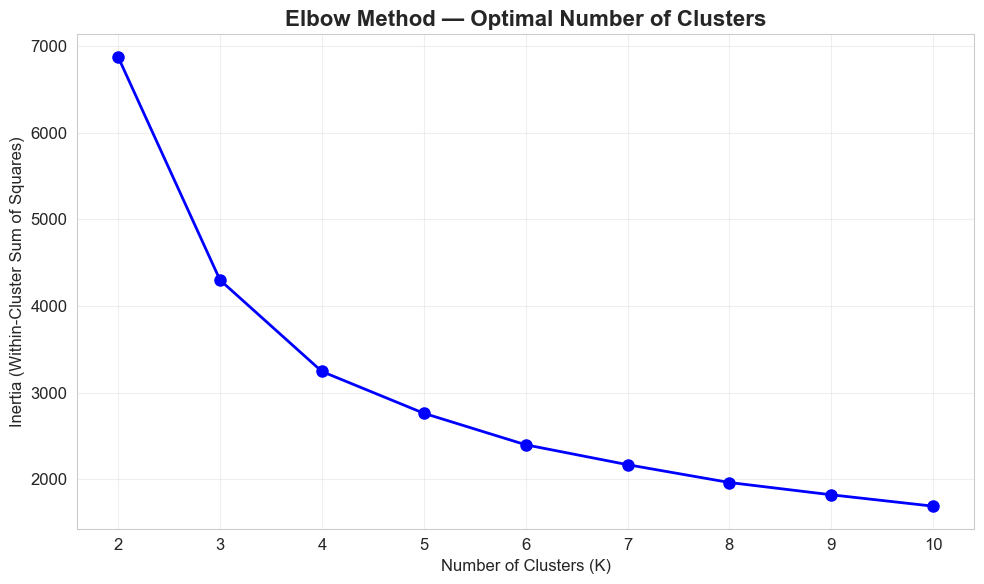

In [9]:
# Elbow Method to determine optimal K
inertias = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    kmeans.fit(rfm_scaled)
    inertias.append(kmeans.inertia_)
    print(f'K={k}: Inertia={kmeans.inertia_:.2f}')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
ax.set_title('Elbow Method — Optimal Number of Clusters', fontsize=16, fontweight='bold')
ax.set_xlabel('Number of Clusters (K)', fontsize=12)
ax.set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Choose optimal K based on elbow (typically 3-5 for RFM)
# Calculate the rate of decrease to find the elbow programmatically
diffs = np.diff(inertias)
diffs2 = np.diff(diffs)
optimal_k = list(K_range)[np.argmax(diffs2) + 2]  # +2 because of double diff offset
# Ensure reasonable range
if optimal_k < 3:
    optimal_k = 4
elif optimal_k > 6:
    optimal_k = 4
    
print(f'Selected optimal K = {optimal_k}')

# Fit final model
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10, max_iter=300)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

print(f'\nCluster distribution:')
print(rfm['Cluster'].value_counts().sort_index())

Selected optimal K = 4

Cluster distribution:
Cluster
0    1377
1     938
2     571
3    1452
Name: count, dtype: int64


## 10. Cluster Visualization

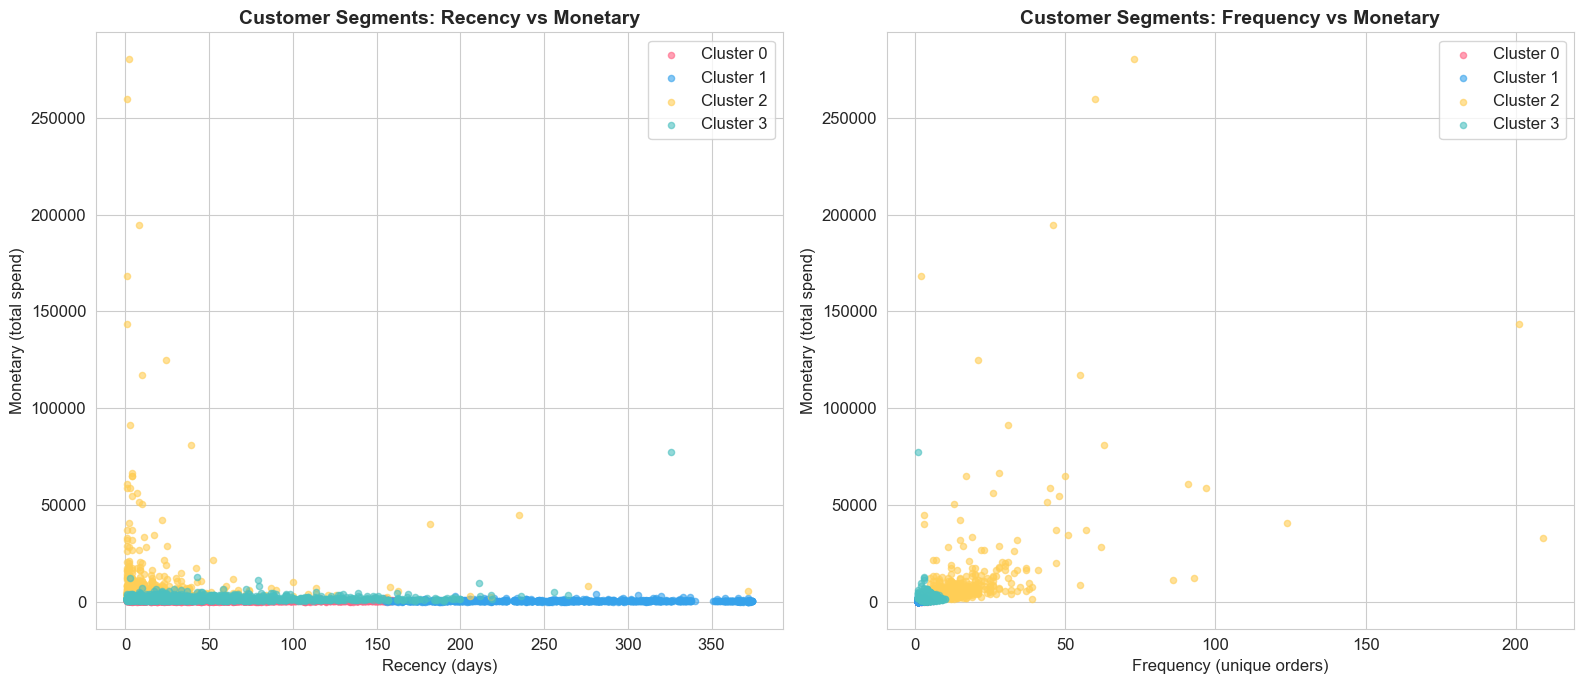

In [11]:
# Scatter plot 1: Recency vs Monetary
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colors = ['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0', '#9966FF', '#FF9F40']

for cluster in sorted(rfm['Cluster'].unique()):
    mask = rfm['Cluster'] == cluster
    axes[0].scatter(rfm[mask]['Recency'], rfm[mask]['Monetary'], 
                    c=colors[cluster % len(colors)], label=f'Cluster {cluster}', 
                    alpha=0.6, s=20)

axes[0].set_title('Customer Segments: Recency vs Monetary', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Recency (days)', fontsize=12)
axes[0].set_ylabel('Monetary (total spend)', fontsize=12)
axes[0].legend()

# Scatter plot 2: Frequency vs Monetary
for cluster in sorted(rfm['Cluster'].unique()):
    mask = rfm['Cluster'] == cluster
    axes[1].scatter(rfm[mask]['Frequency'], rfm[mask]['Monetary'],
                    c=colors[cluster % len(colors)], label=f'Cluster {cluster}',
                    alpha=0.6, s=20)

axes[1].set_title('Customer Segments: Frequency vs Monetary', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequency (unique orders)', fontsize=12)
axes[1].set_ylabel('Monetary (total spend)', fontsize=12)
axes[1].legend()

plt.tight_layout()
plt.savefig('outputs/cluster_scatter_plots.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Cluster Profiling

In [12]:
# Calculate mean feature values per cluster
cluster_profile = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].agg(['mean', 'median', 'count']).round(2)
print('Cluster Profiles (Mean & Median):')
print('='*70)
print(cluster_profile)

# Simplified profile
profile_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean', 
    'Monetary': 'mean',
    'CustomerID': 'count'
}).round(2)
profile_summary.columns = ['Avg Recency (days)', 'Avg Frequency', 'Avg Monetary', 'Customer Count']
print(f'\nSimplified Cluster Profile:')
print(profile_summary)

Cluster Profiles (Mean & Median):
        Recency              Frequency              Monetary               
           mean median count      mean median count     mean   median count
Cluster                                                                    
0         58.04   51.0  1377      1.51    1.0  1377   384.22   341.36  1377
1        259.41  255.0   938      1.37    1.0   938   385.39   294.18   938
2         19.77   10.0   571     15.84   11.0   571  9823.43  4521.49   571
3         46.06   31.0  1452      4.21    4.0  1452  1644.26  1316.16  1452

Simplified Cluster Profile:
         Avg Recency (days)  Avg Frequency  Avg Monetary  Customer Count
Cluster                                                                 
0                     58.04           1.51        384.22            1377
1                    259.41           1.37        385.39             938
2                     19.77          15.84       9823.43             571
3                     46.06           4.

In [13]:
# Assign business labels based on actual cluster statistics
# We label each cluster by comparing its RFM values to the overall mean
overall_means = rfm[['Recency', 'Frequency', 'Monetary']].mean()
print(f'Overall Means: Recency={overall_means["Recency"]:.1f}, Frequency={overall_means["Frequency"]:.1f}, Monetary={overall_means["Monetary"]:.1f}')

cluster_labels = {}
for cluster_id in sorted(rfm['Cluster'].unique()):
    cluster_data = rfm[rfm['Cluster'] == cluster_id]
    avg_r = cluster_data['Recency'].mean()
    avg_f = cluster_data['Frequency'].mean()
    avg_m = cluster_data['Monetary'].mean()
    
    # Classify based on RFM relative to overall means
    low_recency = avg_r < overall_means['Recency']  # recent = good
    high_freq = avg_f > overall_means['Frequency']
    high_monetary = avg_m > overall_means['Monetary']
    
    if low_recency and high_freq and high_monetary:
        label = 'Champions (High-Value Loyal)'
    elif low_recency and high_freq:
        label = 'Loyal Customers'
    elif low_recency and high_monetary:
        label = 'Big Spenders (Recent)'
    elif low_recency and not high_freq and not high_monetary:
        label = 'New/Promising Customers'
    elif not low_recency and high_freq and high_monetary:
        label = 'At-Risk High-Value'
    elif not low_recency and high_freq:
        label = 'At-Risk Loyal'
    elif not low_recency and not high_freq and not high_monetary:
        label = 'Lost/Inactive Customers'
    else:
        label = 'Needs Attention'
    
    cluster_labels[cluster_id] = label
    print(f'\nCluster {cluster_id}: "{label}"')
    print(f'  Avg Recency: {avg_r:.1f} days (overall: {overall_means["Recency"]:.1f})')
    print(f'  Avg Frequency: {avg_f:.1f} orders (overall: {overall_means["Frequency"]:.1f})')
    print(f'  Avg Monetary: {avg_m:.1f} (overall: {overall_means["Monetary"]:.1f})')
    print(f'  Customers: {len(cluster_data):,}')

rfm['Segment'] = rfm['Cluster'].map(cluster_labels)

Overall Means: Recency=92.5, Frequency=4.3, Monetary=2048.7

Cluster 0: "New/Promising Customers"
  Avg Recency: 58.0 days (overall: 92.5)
  Avg Frequency: 1.5 orders (overall: 4.3)
  Avg Monetary: 384.2 (overall: 2048.7)
  Customers: 1,377

Cluster 1: "Lost/Inactive Customers"
  Avg Recency: 259.4 days (overall: 92.5)
  Avg Frequency: 1.4 orders (overall: 4.3)
  Avg Monetary: 385.4 (overall: 2048.7)
  Customers: 938

Cluster 2: "Champions (High-Value Loyal)"
  Avg Recency: 19.8 days (overall: 92.5)
  Avg Frequency: 15.8 orders (overall: 4.3)
  Avg Monetary: 9823.4 (overall: 2048.7)
  Customers: 571

Cluster 3: "New/Promising Customers"
  Avg Recency: 46.1 days (overall: 92.5)
  Avg Frequency: 4.2 orders (overall: 4.3)
  Avg Monetary: 1644.3 (overall: 2048.7)
  Customers: 1,452


**Observation:** Each cluster has been assigned a business-meaningful label based on how its average RFM values compare to the overall averages. These labels reflect actual customer behaviour patterns found in the data.

## 12. Customers per Cluster (Bar Chart)

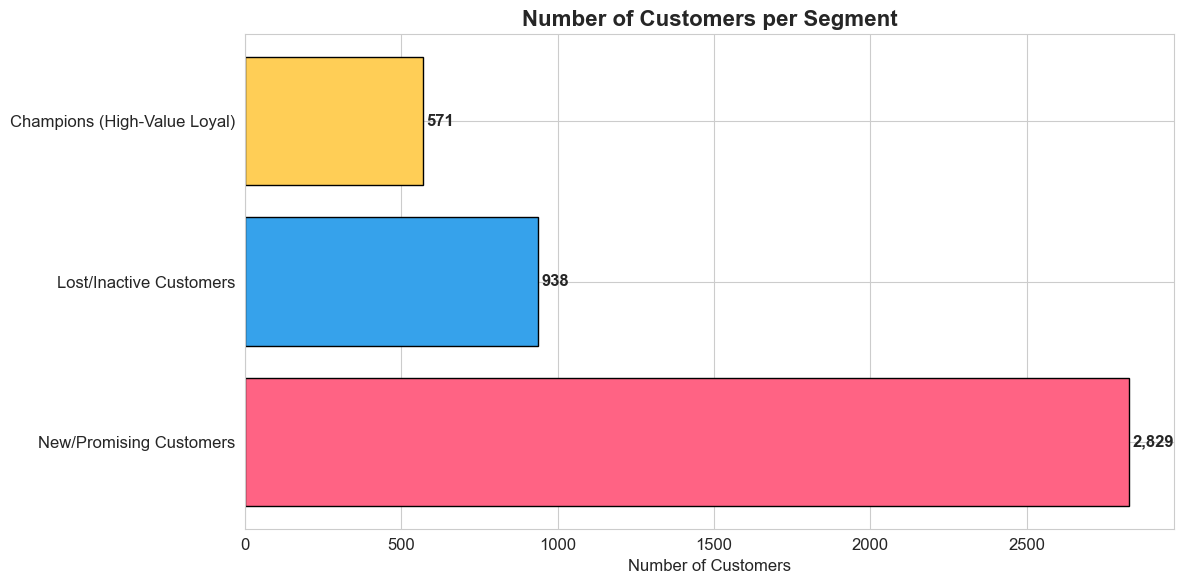


Customer Count by Segment:
  New/Promising Customers: 2,829 customers (65.2%)
  Lost/Inactive Customers: 938 customers (21.6%)
  Champions (High-Value Loyal): 571 customers (13.2%)


In [14]:
# Bar chart: number of customers per cluster
segment_counts = rfm['Segment'].value_counts()

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(segment_counts.index, segment_counts.values, 
               color=colors[:len(segment_counts)], edgecolor='black')

# Add count labels on bars
for bar, count in zip(bars, segment_counts.values):
    ax.text(bar.get_width() + 10, bar.get_y() + bar.get_height()/2, 
            f'{count:,}', va='center', fontweight='bold')

ax.set_title('Number of Customers per Segment', fontsize=16, fontweight='bold')
ax.set_xlabel('Number of Customers', fontsize=12)
plt.tight_layout()
plt.savefig('outputs/customers_per_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nCustomer Count by Segment:')
for seg, count in segment_counts.items():
    pct = count / len(rfm) * 100
    print(f'  {seg}: {count:,} customers ({pct:.1f}%)')

## 13. Marketing Recommendations by Segment

In [15]:
# Generate marketing recommendations based on actual segment profiles
recommendations = {
    'Champions (High-Value Loyal)': 
        'These are your best customers. Reward them with exclusive loyalty programs, '
        'early access to new products, and VIP perks. Consider referral bonuses to leverage '
        'their advocacy. Do NOT over-discount — they already buy frequently at full price.',
    
    'Loyal Customers': 
        'Frequent buyers who may not spend the most per order. Upsell and cross-sell '
        'complementary products. Introduce bundle deals to increase average order value. '
        'Personalized product recommendations based on purchase history.',
    
    'Big Spenders (Recent)': 
        'High-value recent customers who buy less frequently. Send timely follow-up emails '
        'with product suggestions. Create urgency with limited-time premium offers. '
        'Focus on building habit through subscription or auto-replenishment options.',
    
    'New/Promising Customers': 
        'Recently acquired customers with growth potential. Send welcome series emails. '
        'Offer first-purchase discounts on next orders. Educate them about product range. '
        'Monitor engagement closely in the first 90 days.',
    
    'At-Risk High-Value': 
        'Previously high-value customers who have not purchased recently. Launch win-back '
        'campaigns with personalized "We miss you" messaging. Offer strong incentives '
        '(e.g., 20% off) since the cost of losing these customers is high.',
    
    'At-Risk Loyal': 
        'Previously frequent customers drifting away. Survey them to understand dissatisfaction. '
        'Offer renewal discounts. Highlight new arrivals and improvements since their last visit.',
    
    'Lost/Inactive Customers': 
        'Customers who have not purchased in a long time and spent little. Attempt one '
        'reactivation campaign with a compelling offer. If no response, reduce marketing '
        'spend on this segment and reallocate budget to higher-value segments.',
    
    'Needs Attention': 
        'Monitor this segment closely. Analyze purchase patterns for sub-segments. '
        'Test different marketing approaches (email, social, retargeting) to find what resonates.'
}

print('='*70)
print('MARKETING RECOMMENDATIONS BY CUSTOMER SEGMENT')
print('='*70)

for segment in rfm['Segment'].unique():
    count = len(rfm[rfm['Segment'] == segment])
    pct = count / len(rfm) * 100
    rec = recommendations.get(segment, 'Analyze this segment further for tailored recommendations.')
    
    print(f'\n--- {segment} ({count:,} customers, {pct:.1f}%) ---')
    print(f'Recommendation: {rec}')

MARKETING RECOMMENDATIONS BY CUSTOMER SEGMENT

--- New/Promising Customers (2,829 customers, 65.2%) ---
Recommendation: Recently acquired customers with growth potential. Send welcome series emails. Offer first-purchase discounts on next orders. Educate them about product range. Monitor engagement closely in the first 90 days.

--- Champions (High-Value Loyal) (571 customers, 13.2%) ---
Recommendation: These are your best customers. Reward them with exclusive loyalty programs, early access to new products, and VIP perks. Consider referral bonuses to leverage their advocacy. Do NOT over-discount — they already buy frequently at full price.

--- Lost/Inactive Customers (938 customers, 21.6%) ---
Recommendation: Customers who have not purchased in a long time and spent little. Attempt one reactivation campaign with a compelling offer. If no response, reduce marketing spend on this segment and reallocate budget to higher-value segments.


## 14. Conclusion

This analysis successfully segmented customers using RFM analysis and K-Means clustering:

1. **Data Preparation:** The UCI Online Retail dataset was cleaned by removing cancelled orders, null customer IDs, and invalid transactions.
2. **RFM Engineering:** Three behavioural features — Recency, Frequency, and Monetary — were computed for each customer.
3. **Normalization:** Features were log-transformed and standardized using `StandardScaler` before clustering.
4. **Clustering:** The Elbow Method was used to determine the optimal number of clusters, and K-Means was applied.
5. **Profiling:** Each cluster was profiled with mean RFM values and assigned a meaningful business label.
6. **Recommendations:** Tailored marketing strategies were proposed for each customer segment.

The segmentation enables the business to move from a one-size-fits-all marketing approach to a targeted strategy, potentially improving customer retention and revenue.

---

*Analysis completed as part of the Oasis Infobyte Data Analytics Internship.*